# Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Read data

In [2]:
df = pd.read_csv(r'/Users/pawn/Desktop/NTI/diabetes_risk.csv')
df.head()

,glucose,bmi,blood_pressure,age,insulin,diabetes_pedigree,diabetic
0,137.6,25.6,88.0,62,141.1,1.397,0
1,118.4,31.8,91.0,60,139.1,1.437,0
2,NaN,41.7,113.0,47,NaN,1.152,1
3,128.3,27.4,111.0,49,156.1,1.083,1
4,NaN,30.4,138.0,49,216.2,0.333,1


In [3]:
df.shape

(600, 7)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   glucose            552 non-null    float64
 1   bmi                524 non-null    float64
 2   blood_pressure     541 non-null    float64
 3   age                600 non-null    int64  
 4   insulin            517 non-null    float64
 5   diabetes_pedigree  600 non-null    float64
 6   diabetic           600 non-null    int64  
dtypes: float64(5), int64(2)
memory usage: 32.9 KB


In [5]:
df.describe()

,glucose,bmi,blood_pressure,age,insulin,diabetes_pedigree,diabetic
count,552.000000,524.000000,541.000000,600.000000,517.000000,600.000000,600.000000
mean,131.274457,29.982252,104.573013,49.110000,176.498066,1.169928,0.503333
std,18.223714,6.441240,13.830212,11.597791,50.893452,0.349882,0.500406
min,70.000000,15.000000,66.000000,20.000000,0.000000,0.050000,0.000000
25%,119.375000,25.400000,95.000000,40.000000,144.000000,0.933750,0.000000
50%,130.600000,29.150000,105.000000,49.000000,182.000000,1.154500,1.000000
75%,141.825000,33.725000,114.000000,58.000000,210.000000,1.399250,1.000000
max,200.000000,50.000000,140.000000,80.000000,300.000000,2.500000,1.000000


# Data Visualization

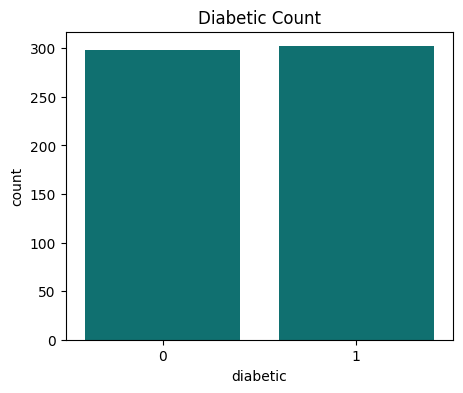

In [6]:
plt.figure(figsize=(5, 4))
sns.countplot(x='diabetic', data=df, color='teal')
plt.title('Diabetic Count')
plt.show()

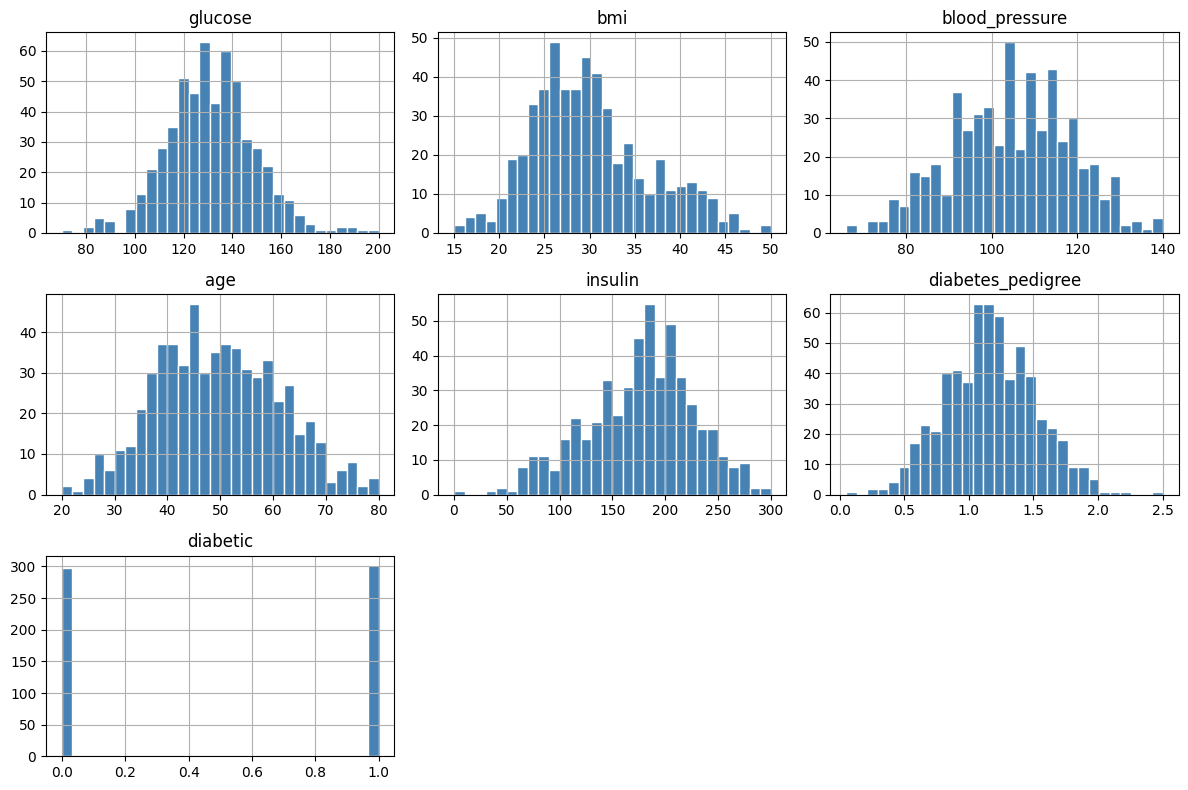

In [7]:
df.hist(figsize=(12, 8), bins=30, color='steelblue', edgecolor='white')
plt.tight_layout()
plt.show()

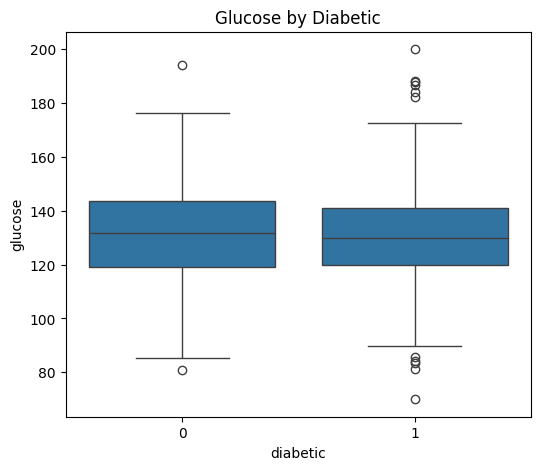

In [8]:
plt.figure(figsize=(6, 5))
sns.boxplot(x='diabetic', y='glucose', data=df)
plt.title('Glucose by Diabetic')
plt.show()

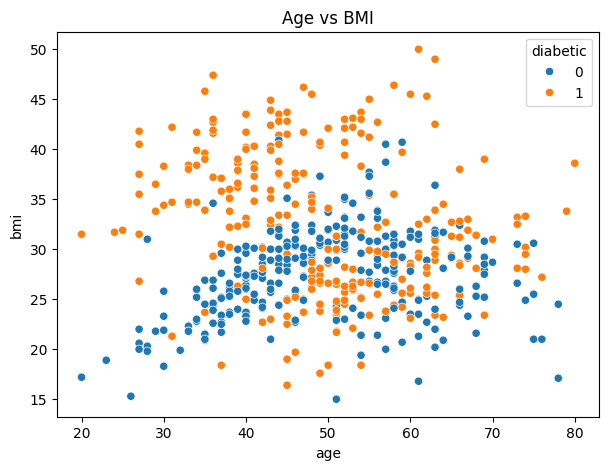

In [9]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x='age', y='bmi', hue='diabetic', data=df)
plt.title('Age vs BMI')
plt.show()

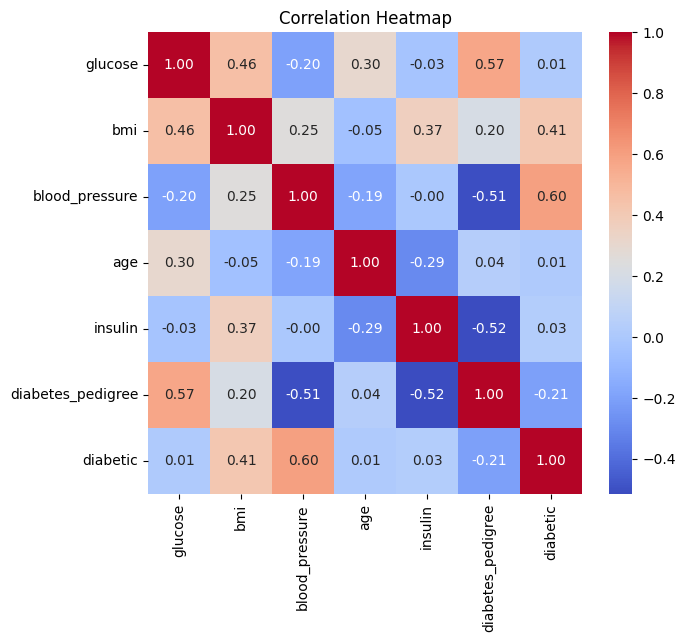

In [10]:
plt.figure(figsize=(7, 6))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

# Data Cleaning duplicated

In [11]:
print('Number of duplicate rows : ', df.duplicated().sum())
df.drop_duplicates(inplace=True)

Number of duplicate rows :  0


# Data Cleaning missing Value

In [12]:
df.isnull().sum().sort_values(ascending=False)

insulin              83
bmi                  76
blood_pressure       59
glucose              48
age                   0
diabetes_pedigree     0
diabetic              0
dtype: int64

In [13]:
df[['glucose', 'bmi', 'blood_pressure', 'insulin']].skew()

glucose           0.169323
bmi               0.542608
blood_pressure   -0.089801
insulin          -0.357688
dtype: float64

Insulin is skewed so it gets the median, the other columns get the mean

In [14]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
df[['glucose', 'bmi', 'blood_pressure']] = imputer.fit_transform(df[['glucose', 'bmi', 'blood_pressure']])

imputer = SimpleImputer(missing_values=np.nan, strategy='median')
df[['insulin']] = imputer.fit_transform(df[['insulin']])

In [15]:
df.isnull().sum().sort_values(ascending=False)

glucose              0
bmi                  0
blood_pressure       0
age                  0
insulin              0
diabetes_pedigree    0
diabetic             0
dtype: int64

# Outliers

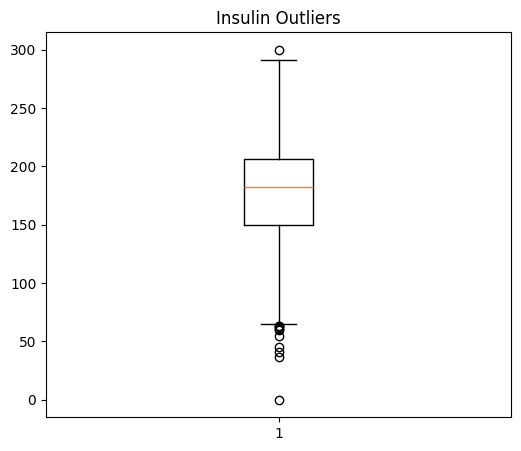

In [16]:
plt.figure(figsize=(6, 5))
plt.boxplot(df['insulin'])
plt.title('Insulin Outliers')
plt.show()

## IQR

In [17]:
q1 = df['insulin'].quantile(0.25)
q3 = df['insulin'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

df = df[(df['insulin'] >= lower) & (df['insulin'] <= upper)]
df.reset_index(drop=True, inplace=True)
df.shape

(589, 7)

# Split data

In [18]:
X = df.drop('diabetic', axis=1)
y = df[['diabetic']]
y.value_counts()

diabetic
1           295
0           294
Name: count, dtype: int64

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=100, stratify=y)
print('X_train = ', X_train.shape, ' y_train = ', y_train.shape)
print('X_test  = ', X_test.shape, ' y_test  = ', y_test.shape)

X_train =  (471, 6)  y_train =  (471, 1)
X_test  =  (118, 6)  y_test  =  (118, 1)


# Scaling

In [20]:
from sklearn.preprocessing import MinMaxScaler

my_scaler = MinMaxScaler(feature_range=(0, 1))
X_train = my_scaler.fit_transform(X_train)
X_test = my_scaler.transform(X_test)

# Models

## Logistic Regression

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

y_train = y_train.values.ravel()
y_test = y_test.values.ravel()

model = LogisticRegression(C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, model.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Train accuracy: 0.8131634819532909
Test accuracy: 0.8135593220338984
              precision    recall  f1-score   support

           0       0.82      0.80      0.81        59
           1       0.80      0.83      0.82        59

    accuracy                           0.81       118
   macro avg       0.81      0.81      0.81       118
weighted avg       0.81      0.81      0.81       118



## KNN

In [22]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, knn.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

Train accuracy: 0.9023354564755839
Test accuracy: 0.8898305084745762
              precision    recall  f1-score   support

           0       0.93      0.85      0.88        59
           1       0.86      0.93      0.89        59

    accuracy                           0.89       118
   macro avg       0.89      0.89      0.89       118
weighted avg       0.89      0.89      0.89       118



## Naive Bayes

In [23]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

y_pred_gnb = gnb.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, gnb.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred_gnb))
print(classification_report(y_test, y_pred_gnb))

Train accuracy: 0.7940552016985138
Test accuracy: 0.8220338983050848
              precision    recall  f1-score   support

           0       0.82      0.83      0.82        59
           1       0.83      0.81      0.82        59

    accuracy                           0.82       118
   macro avg       0.82      0.82      0.82       118
weighted avg       0.82      0.82      0.82       118



## SVC

In [24]:
from sklearn.svm import SVC

svc = SVC(C=0.1, kernel='linear', gamma='auto')
svc.fit(X_train, y_train)

y_pred_svc = svc.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, svc.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred_svc))
print(classification_report(y_test, y_pred_svc))

Train accuracy: 0.802547770700637
Test accuracy: 0.8050847457627118
              precision    recall  f1-score   support

           0       0.82      0.78      0.80        59
           1       0.79      0.83      0.81        59

    accuracy                           0.81       118
   macro avg       0.81      0.81      0.80       118
weighted avg       0.81      0.81      0.80       118



## Decision Tree

In [25]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt = DecisionTreeClassifier(criterion='gini', max_depth=5, min_samples_split=10, min_samples_leaf=5, random_state=100)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, dt.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

Train accuracy: 0.8683651804670913
Test accuracy: 0.7542372881355932
              precision    recall  f1-score   support

           0       0.83      0.64      0.72        59
           1       0.71      0.86      0.78        59

    accuracy                           0.75       118
   macro avg       0.77      0.75      0.75       118
weighted avg       0.77      0.75      0.75       118



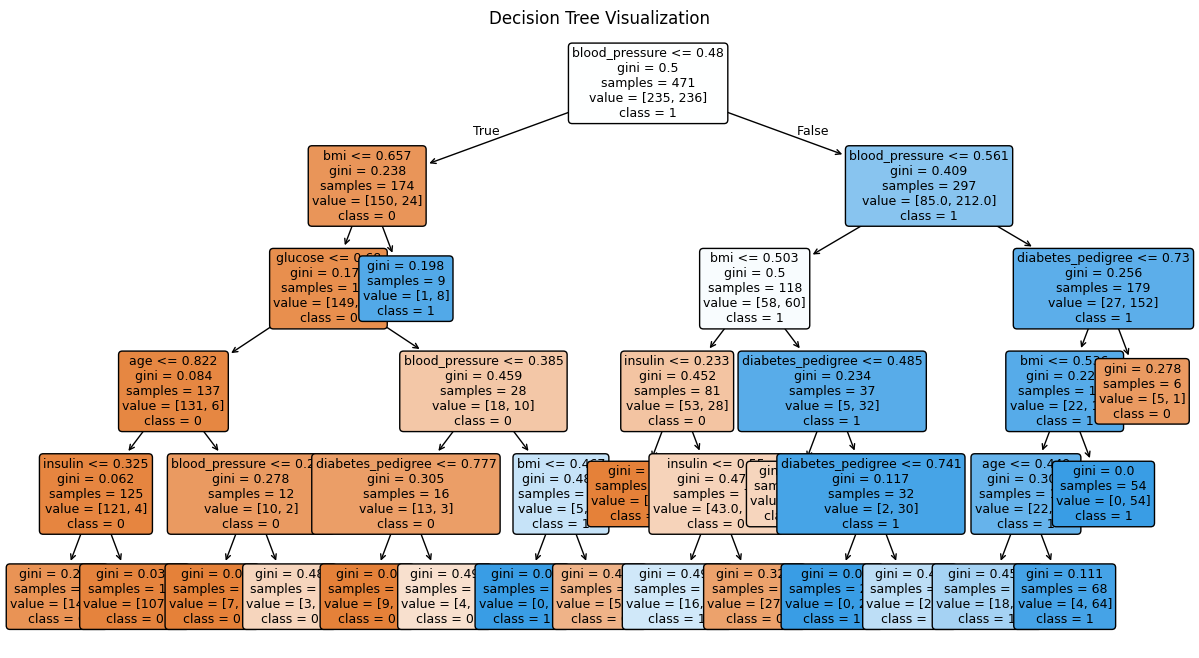

In [26]:
plt.figure(figsize=(15, 8))
plot_tree(dt, feature_names=X.columns.tolist(), class_names=[str(c) for c in dt.classes_], filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree Visualization')
plt.show()

## GridSearchCV (Decision Tree)

In [27]:
from sklearn.model_selection import GridSearchCV

grid_params = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 5, 10]
}

grid = GridSearchCV(estimator=DecisionTreeClassifier(random_state=100), param_grid=grid_params, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print(grid.best_params_)
y_pred_best = best_model.predict(X_test)
print('Test accuracy:', accuracy_score(y_test, y_pred_best))
print(classification_report(y_test, y_pred_best))

{'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 20}
Test accuracy: 0.8050847457627118
              precision    recall  f1-score   support

           0       0.83      0.76      0.80        59
           1       0.78      0.85      0.81        59

    accuracy                           0.81       118
   macro avg       0.81      0.81      0.80       118
weighted avg       0.81      0.81      0.80       118



## Random Forest

In [28]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, rf.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Train accuracy: 1.0
Test accuracy: 0.847457627118644
              precision    recall  f1-score   support

           0       0.87      0.81      0.84        59
           1       0.83      0.88      0.85        59

    accuracy                           0.85       118
   macro avg       0.85      0.85      0.85       118
weighted avg       0.85      0.85      0.85       118



## Models comparison

Decision Tree           0.754237
SVC                     0.805085
Decision Tree (Grid)    0.805085
Logistic Regression     0.813559
Naive Bayes             0.822034
Random Forest           0.847458
KNN                     0.889831
dtype: float64


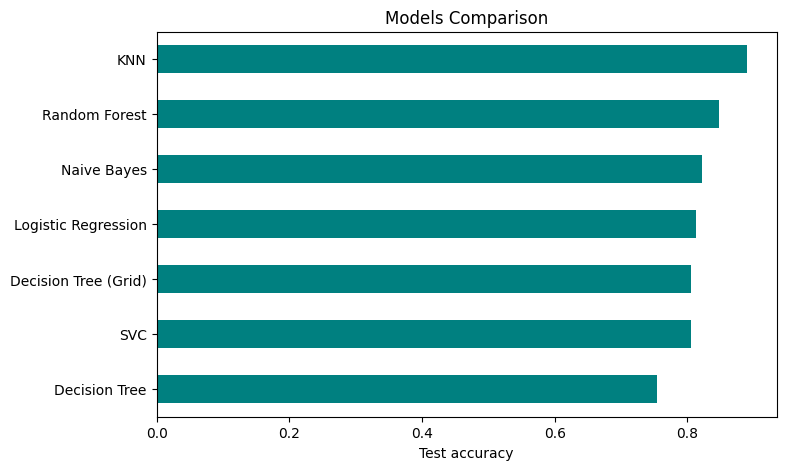

In [29]:
results = {
    'Logistic Regression': accuracy_score(y_test, y_pred),
    'KNN': accuracy_score(y_test, y_pred_knn),
    'Naive Bayes': accuracy_score(y_test, y_pred_gnb),
    'SVC': accuracy_score(y_test, y_pred_svc),
    'Decision Tree': accuracy_score(y_test, y_pred_dt),
    'Decision Tree (Grid)': accuracy_score(y_test, y_pred_best),
    'Random Forest': accuracy_score(y_test, y_pred_rf),
}
results = pd.Series(results).sort_values()
print(results)

plt.figure(figsize=(8, 5))
results.plot(kind='barh', color='teal')
plt.xlabel('Test accuracy')
plt.title('Models Comparison')
plt.show()

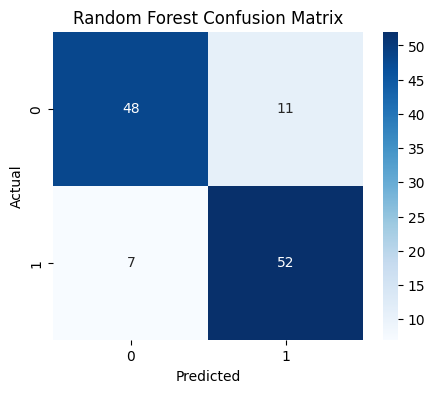

In [30]:
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues')
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()